## ST3131 Assignment 2: Predicting HDB Resale Prices ##

## Part 0: Problem and plan

### Goal: 
find the “best” linear regression model for predicting the resale price of an HDB flat. “Best” balances two aims that can pull against each other: 
    - (i) predictive accuracy on unseen transactions (the Jan–Mar 2018 test set), and 
    - (ii) a model that stays interpretable and statistically adequate (assumptions approximately satisfied).

Data and evaluation design. The model is built only on the 2017 transactions (training set). The Jan–Mar 2018 transactions (test set) are never used for fitting, selection or transformation choices, and are touched once at the end for the final evaluation. Because candidate models are compared on the training data, model selection relies on in-sample criteria that penalise complexity (adjusted $R^2$, residual standard error, AIC, BIC), together with t-tests and partial F-tests. These criteria are only compared between models with the same response and the same data.

### Plan ###

***EDA***: 
1. examine the response (skewness, need for a transform) and how each regressor relates to it. Convert the text columns (remaining_lease, storey_range) into numbers, and define location at region and town level using outside knowledge of Singapore.

***M0***: 

a deliberately simple additive model for the raw price with at least six regressors, as the baseline.

***Adequacy checking of M0***: 

residual plots, normal QQ plot, Box-Cox, VIF, and outliers/influence. Each problem found is treated in turn:
1. non-constant variance and right skew → log transform of price (M1);
2. region too coarse a location measure → town (M2);
3. multicollinearity and curvature in floor area → drop flat_type and use √floor_area_sqm (M3).

***Model selection***: 

compare candidate models on the training data by adjusted $R^2$, RSE, AIC and BIC, then run a backward-elimination check on the chosen model. 

***Final model and test evaluation***: 

state the final model, re-check its adequacy, interpret the coefficients, then predict the 2018 test set using the 2017 fit. Report RMSE and $R^2_{\text{test}}$ on both the log scale (the model’s response) and the price scale, and compare with the training values to check for overfitting.

In [1]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

TRAIN_PATH = 'hdb-resale-whole-2017.csv'
TEST_PATH = 'hdb-resale-Jan-to-Mar-2018.csv'

os.chdir('/Users/gianice/Desktop/School/Y3S1/ST3131')
df_train = pd.read_csv(TRAIN_PATH)


In [2]:
def SR(model):
    # standardized (internally studentized) residuals
    return model.get_influence().resid_studentized_internal

def resid_plots(model, data, xcols, title="Model", alpha="auto", s=4, cell=3.6, fig_label = ''):
    """QQ plot of SR, SR vs fitted, and SR vs each regressor in xcols,
    laid out on a near-square grid (about sqrt(k) x sqrt(k)).
    alpha='auto' lowers point opacity as n grows, so dense regions show up darker."""
    sr = SR(model)
    n = len(sr)
    if alpha == "auto":
        alpha = float(np.clip(600 / n, 0.05, 0.6))      # n=20,509 -> about 0.05; small n -> 0.6

    k = 2 + len(xcols)                                   # number of panels
    ncols = int(np.ceil(np.sqrt(k)))
    nrows = int(np.ceil(k / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols, cell * nrows))
    ax = np.atleast_1d(axes).ravel()

    # 1) QQ plot of SR
    sm.qqplot(sr, line="45", ax=ax[0], markersize=2, alpha=max(alpha, 0.15))
    ax[0].get_lines()[1].set_color("red")
    ax[0].set_title(f"QQ plot of SR ({title})")

    # 2) SR vs fitted, 3+) SR vs each regressor
    ax[1].scatter(model.fittedvalues, sr, alpha = alpha, s=s, rasterized=True)
    ax[1].set_xlabel("Fitted"); ax[1].set_title("SR vs Fitted")
    for i, xc in enumerate(xcols):
        ax[2 + i].scatter(data[xc], sr, s=s, alpha=alpha, rasterized=True)
        ax[2 + i].set_xlabel(xc); ax[2 + i].set_title(f"SR vs {xc}")

    # reference lines on every residual panel
    for a in ax[1:k]:
        a.axhline(0, color="red", lw=1)
        a.axhline(3, color="blue", ls="dotted", lw=1)
        a.axhline(-3, color="blue", ls="dotted", lw=1)
        a.set_ylabel("SR")

    for a in ax[k:]:                                     # hide unused panels
        a.set_visible(False)

    prefix = f"{fig_label}: " if fig_label else ""
    fig.suptitle(f"{prefix}{title} residual diagnostics (n = {n:,})", y=1.0)
    plt.tight_layout(); plt.show()
    return sr

def vif_table(model):
    """VIF for every regressor of a fitted statsmodels OLS model (intercept excluded)."""
    X = model.model.exog
    names = model.model.exog_names
    out = pd.DataFrame({
        'variable': names,
        'VIF': [vif(X, i) for i in range(X.shape[1])]
    })
    return out[out['variable'] != 'Intercept'].sort_values('VIF', ascending=False).round(2)


### Part 1: EDA ###

I breakdown my EDA into 4 steps.
- Variable Transformations - to make it standardized / change to numerical value
- Analysis of response(ie: HDB resale price)
- Quantitative Regressors Analysis
- Categorical Regressors Analysis


**Step 1.1: Variable transformations**

| Original variable | New variable | Transformation | Rationale |
|---|---|---|---|
| `resale_price` | `price_k` | Divided by 1,000 | Expresses price in thousands of SGD for readability |
| `remaining_lease` | `lease_years` | Text ("61 years 04 months") converted to decimal years | Numeric form required for regression |
| `storey_range` | `storey` | Mid-point of each range (e.g. "04 TO 06" → 5) | Ordered bins with a roughly linear effect; avoids 16 dummy variables |
| `month` | `month` | only stores the month, in numerical format (e.g. "2017-01" to 1) | transform into quantitative regressor for easier comparison |

In [3]:
df_train['price_k'] = df_train['resale_price'] / 1000

def lease_years(s):
    p=s.split(); y=int(p[0]); mth=int(p[2]) if len(p)>2 else 0
    return y+mth/12

def midpoint_storey(s):
    p=s.split(); a=int(p[0]); b=int(p[2])
    return (a + b) / 2

def month_from_date(s):
    p=s.split('-'); return int(p[1])

df_train['lease_years'] = df_train['remaining_lease'].apply(lease_years)
df_train['storey'] = df_train['storey_range'].apply(midpoint_storey)
df_train['month'] = df_train['month'].apply(month_from_date)
df_train.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,price_k,lease_years,storey
0,1,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0,232.0,61.333333,11.0
1,1,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0,250.0,60.583333,2.0
2,1,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0,262.0,62.416667,2.0
3,1,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0,265.0,62.083333,5.0
4,1,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0,265.0,62.416667,2.0


### Step 1.2: Analysis of Response

median of price 410.0
mean of price 443.88852057145635
SD of price 149.1483201644743
range of the price: 175.0 to 1180.0


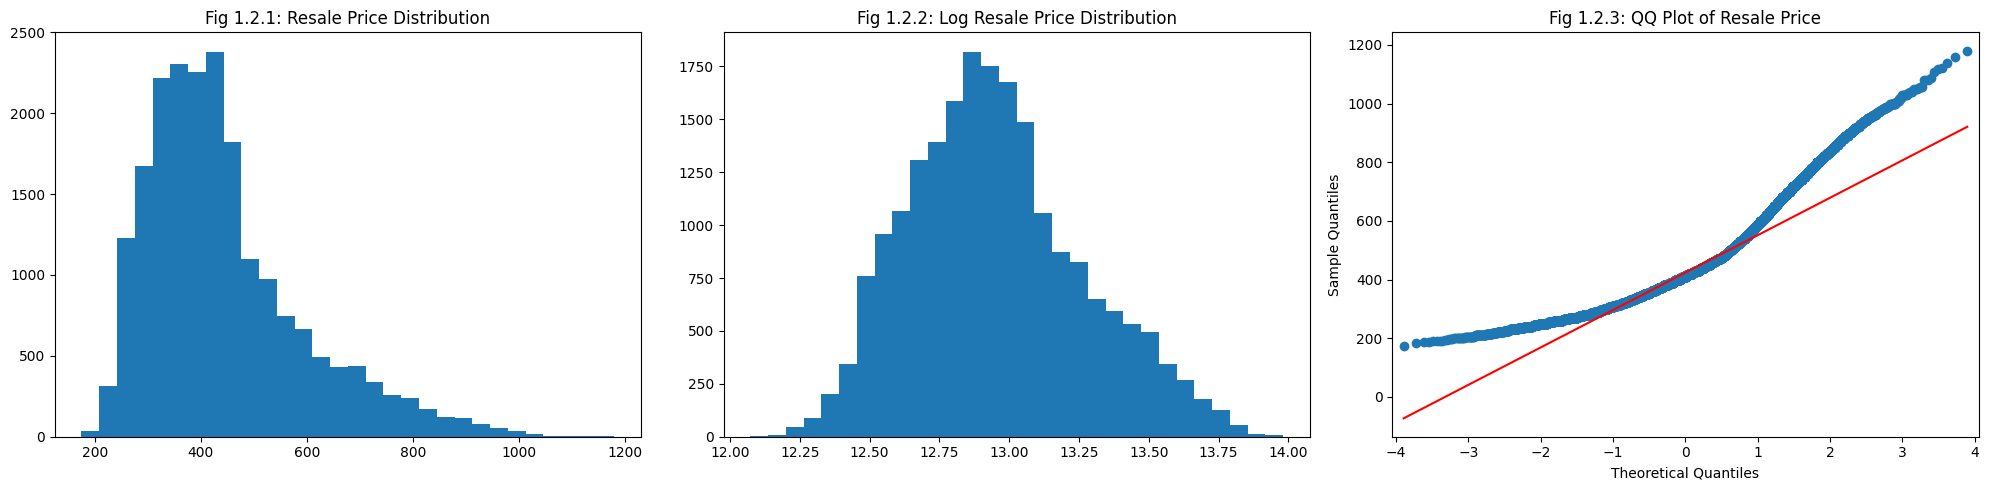

skewness price_k = 1.18, log price = 0.40
       median price by month (k)
month                           
1                          405.0
2                          415.0
3                          415.0
4                          408.0
5                          410.0
6                          415.0
7                          405.0
8                          415.0
9                          418.0
10                         410.0
11                         410.0
12                         418.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

print(f'median of price {df_train['price_k'].median()}')
print(f'mean of price {df_train['price_k'].mean()}')
print(f'SD of price {df_train['price_k'].std()}')
print(f'range of the price: {df_train['price_k'].min()} to {df_train['price_k'].max()}')
axes[0].hist(df_train['price_k'], bins=30)
axes[0].set_title('Fig 1.2.1: Resale Price Distribution')

df_train['log_price'] = np.log(df_train['resale_price'])
axes[1].hist(df_train['log_price'], bins=30)
axes[1].set_title('Fig 1.2.2: Log Resale Price Distribution')

sm.qqplot(df_train['price_k'], line='q', ax=axes[2])
axes[2].set_title('Fig 1.2.3: QQ Plot of Resale Price')

plt.tight_layout()
plt.show()

print('skewness price_k = %.2f, log price = %.2f' % (df_train.price_k.skew(), df_train.log_price.skew()))
print(df_train.groupby('month')['price_k'].median().rename('median price by month (k)').to_frame())

**Reading it.** 
1. Price is continuous, positive and **right-skewed** (skew ≈ 1.18, long tail up to $1.1M)
2. QQ curve upwards -> suggest violation of normality assumption -> consider transformation of original $y$
3. log(price) is much more symmetric (skew ≈ 0.40). That's a first hint that a log (or Box-Cox) response will be needed, because skew in $y$ usually shows up as non-constant, skewed residuals.
4. Monthly medians sit in a tight 405–418k band, so the **2017 market was flat**. A time trend adds almost nothing, and extrapolating one into 2018 would be risky, so `t` is left out.

### Step 1.3 : Quantitative Regressors Analysis ###

1. floor_area_sqm
2. lease_years
3. storey
4. month

Based on the above 4 quantitative regressors, I will plot ***scatter plots*** and ***calculate correlations*** for each regressors vs HDB resale price and give comments about the scatter plots.

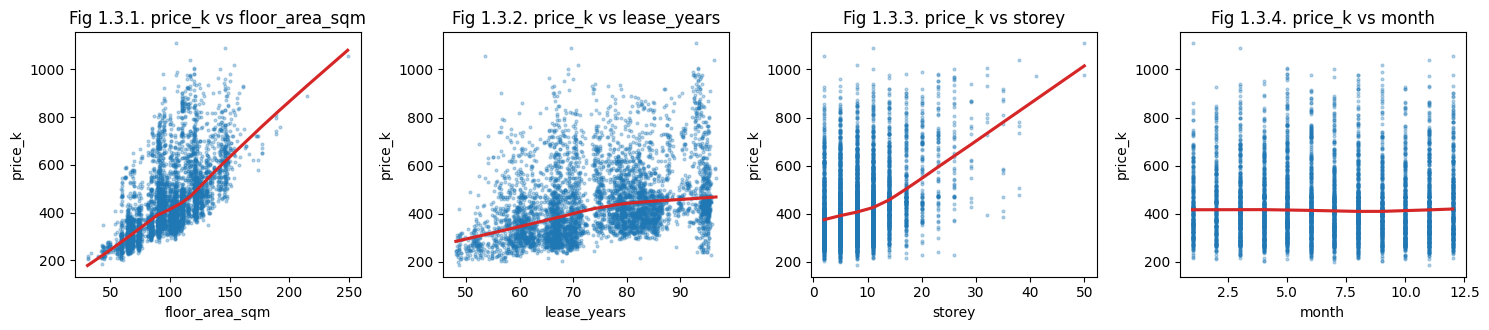

,price_k,floor_area_sqm,lease_years,storey,month
price_k,1.00,0.63,0.35,0.39,0.02
floor_area_sqm,0.63,1.00,0.30,0.05,0.03
lease_years,0.35,0.30,1.00,0.30,0.02
storey,0.39,0.05,0.30,1.00,0.03
month,0.02,0.03,0.02,0.03,1.00


In [5]:
s = df_train.sample(5000, random_state=1)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, v in zip(ax, ['floor_area_sqm','lease_years','storey', 'month']):
    sns.regplot(data=s, x=v, y='price_k', ax=a, scatter_kws=dict(s=4, alpha=.3), lowess=True, line_kws=dict(color='C3'))
    a.set_title(f'Fig 1.3.{ax.tolist().index(a)+1}. price_k vs {v}')
plt.tight_layout(); plt.show()
df_train[['price_k','floor_area_sqm','lease_years','storey','month']].corr().round(2)



**Reading it.** 

| Regressor | Comments |
|---|---|
|`floor_area_sqm`| 1. positive relationship 2. quite linear, but fan out as the floor area increases, which suggests **non constant variance for response** |
| `lease_years` | 1. slightly positive relationship 2. Price rises with remaining lease up to about 75–80 years and then levels off (Fig 1.3.2). 3. outward funnel shape: suggesting **non constant variance** again |
| `storey` |1. positive relationship, quite strong and linear|
| `month` |1. no obvious increase/decreasing relationship, suggesting that **2017 market was flat**. A time trend adds almost nothing, and extrapolating one into 2018 would be risky, so `month` is left out.|

### Step 1.4 : Categorical Regressors ###
1. Town
2. Flat Type
3. Flat Model

***Initial Idea***
- For `Town`, two alternative groupings are considered and compared (criteria mentioned below):
    - URA market segments (CCR, RCR, OCR)
    - Data-driven groups based on the box plot of price by town

- `Flat models` were grouped into four tiers using three criteria: 
    - (i) sample size, since several models have fewer than 35 sales (e.g. Premium Apartment Loft n = 1, Multi Generation n = 4) and cannot support stable coefficients; 
    - (ii) similarity in design type (e.g. all maisonettes together);
    - (iii) proximity of median prices. 
        - Some heterogeneity remains within the Executive and Unique tiers, but these tiers are dominated by a few large models (Apartment and Maisonette; DBSS), so the group effect mainly reflects them. 

- `Flat types` check the sample size and merge group together when sample size is relatively small to reduce variance


***Decision After Box Plot***

- `town`: grouping based on URA market segments, since raw boxplot (Fig 1.4.1) shows large overlap because town is confounded with flat size and lease, which is quite hard to grouped by observation
- `Flat Model`: 
    - **Basic**: ['Standard', 'Simplified', 'New Generation', 'Model A2']
    - **Mainstream**: ['Model A', 'Improved', 'Premium Apartment']
    - **Executive**: ['Apartment', 'Improved-Maisonette', 'Maisonette', 'Adjoined flat', 'Model A-Maisonette', 'Multi Generation', 'Premium Maisonette']
    - **Unique**: ['Terrace', 'DBSS', 'Premium Apartment Loft', 'Type S1', 'Type S2']
- `Flat Type` :
    - 1 ROOM has only 9 sample size -> merge into 2 Room 
    - Multi-generation has only 4 sample size -> merge into Executive


In [6]:
##checking of flat types sample size##
test = df_train.groupby('flat_type').count()
print(test)

                  month  town  block  street_name  storey_range  \
flat_type                                                         
1 ROOM                9     9      9            9             9   
2 ROOM              219   219    219          219           219   
3 ROOM             5047  5047   5047         5047          5047   
4 ROOM             8604  8604   8604         8604          8604   
5 ROOM             5002  5002   5002         5002          5002   
EXECUTIVE          1624  1624   1624         1624          1624   
MULTI-GENERATION      4     4      4            4             4   

                  floor_area_sqm  flat_model  lease_commence_date  \
flat_type                                                           
1 ROOM                         9           9                    9   
2 ROOM                       219         219                  219   
3 ROOM                      5047        5047                 5047   
4 ROOM                      8604        8604       

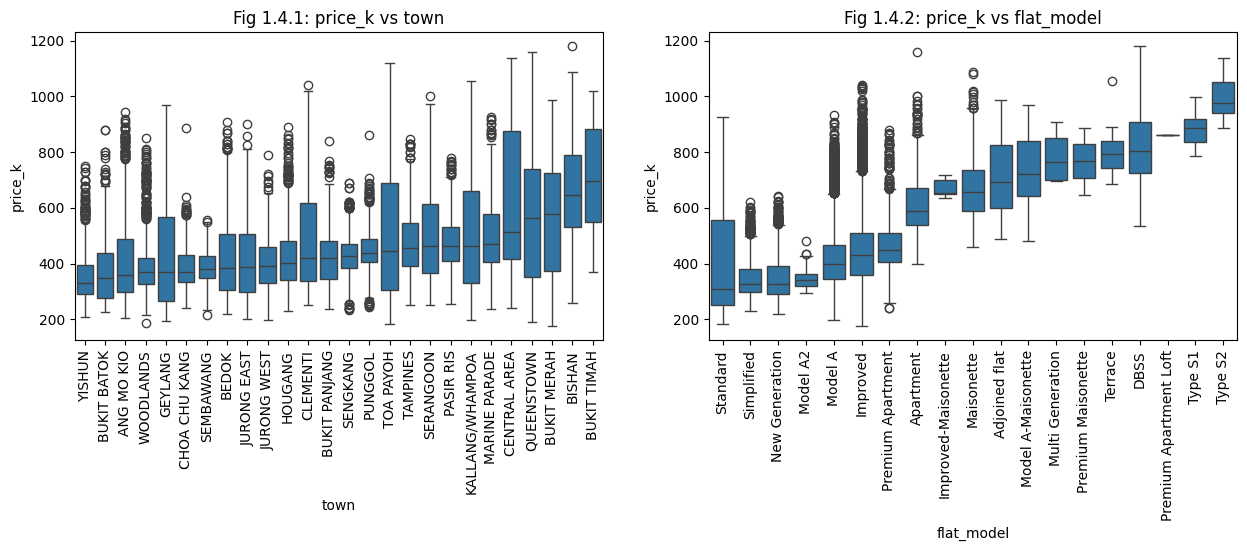

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
order_town = df_train.groupby('town')['price_k'].median().sort_values().index
order_flat_model = df_train.groupby('flat_model')['price_k'].median().sort_values().index

sns.boxplot(data = df_train, x = 'town', y = 'price_k', ax=ax[0], order=order_town)
ax[0].set_title('Fig 1.4.1: price_k vs town')
ax[0].tick_params(axis='x', rotation=90)
sns.boxplot(data = df_train, x = 'flat_model', y = 'price_k', ax=ax[1], order=order_flat_model)
ax[1].set_title('Fig 1.4.2: price_k vs flat_model')
ax[1].tick_params(axis='x', rotation=90)
plt.show()

In [8]:
#------First Grouping of Town by URA Definition ----------
REGION_MKT = {
    # CCR: Core Central Region
    'BUKIT TIMAH': 'CCR',      # D10 (Bukit Timah / Holland)
    'CENTRAL AREA': 'CCR',     # D1/D2/D6/D7 (Raffles Place, Tanjong Pagar, City Hall, Bugis)

    # RCR: Rest of Central Region
    'BUKIT MERAH': 'RCR',      # D3/D4 (Tiong Bahru, Alexandra, Telok Blangah)
    'QUEENSTOWN': 'RCR',       # D3
    'KALLANG/WHAMPOA': 'RCR',  # D12 (Whampoa, Boon Keng, Bendemeer)
    'TOA PAYOH': 'RCR',        # D12
    'GEYLANG': 'RCR',          # D14 (Geylang, Aljunied, Eunos)
    'MARINE PARADE': 'RCR',    # D15
    'BISHAN': 'RCR',           # D20 (Bishan part)

    # OCR: Outside Central Region
    'ANG MO KIO': 'OCR',       # D20 (AMK part)
    'BEDOK': 'OCR',            # D16
    'TAMPINES': 'OCR',         # D18
    'PASIR RIS': 'OCR',        # D18
    'HOUGANG': 'OCR',          # D19
    'PUNGGOL': 'OCR',          # D19
    'SENGKANG': 'OCR',         # D19
    'SERANGOON': 'OCR',        # D19
    'CLEMENTI': 'OCR',         # D5 (Clementi part) / D21
    'JURONG EAST': 'OCR',      # D22
    'JURONG WEST': 'OCR',      # D22
    'BUKIT BATOK': 'OCR',      # D23
    'BUKIT PANJANG': 'OCR',    # D23
    'CHOA CHU KANG': 'OCR',    # D23
    'WOODLANDS': 'OCR',        # D25
    'YISHUN': 'OCR',           # D27
    'SEMBAWANG': 'OCR',        # D27
}

flat_model_mapping = {
    'Standard': 'Basic', 'Simplified': 'Basic', 'New Generation': 'Basic', 'Model A2': 'Basic',
    'Model A': 'Mainstream', 'Improved': 'Mainstream', 'Premium Apartment': 'Mainstream',
    'Apartment': 'Executive', 'Improved-Maisonette': 'Executive', 'Maisonette': 'Executive',
    'Adjoined flat': 'Executive', 'Model A-Maisonette': 'Executive',
    'Multi Generation': 'Executive', 'Premium Maisonette': 'Executive',
    'Terrace': 'Unique', 'DBSS': 'Unique', 'Premium Apartment Loft': 'Unique',
    'Type S1': 'Unique', 'Type S2': 'Unique',
}

df_train['region'] = df_train['town'].map(REGION_MKT)
df_train['flat_model_grouped'] = df_train['flat_model'].map(flat_model_mapping)
df_train['flat_type'] = df_train['flat_type'].replace({'1 ROOM': '1 or 2 ROOM', '2 ROOM': '1 or 2 ROOM', 'EXECUTIVE': 'EXECUTIVE_MULTI', 'MULTI-GENERATION': 'EXECUTIVE_MULTI'})

df_train.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price,price_k,lease_years,storey,log_price,region,flat_model_grouped
0,1,ANG MO KIO,1 or 2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0,232.0,61.333333,11.0,12.354493,OCR,Mainstream
1,1,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0,250.0,60.583333,2.0,12.429216,OCR,Basic
2,1,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0,262.0,62.416667,2.0,12.476100,OCR,Basic
3,1,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0,265.0,62.083333,5.0,12.487485,OCR,Basic
4,1,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0,265.0,62.416667,2.0,12.487485,OCR,Basic


In [9]:
cnt = (df_train.groupby(['flat_model_grouped', 'flat_model'])
       .agg(n=('price_k', 'size'), median_price=('price_k', 'median'))
       .sort_values(['flat_model_grouped', 'median_price']))
print(cnt)
print("models with n < 35:", cnt[cnt['n'] < 35].index.get_level_values('flat_model').tolist())

                                              n  median_price
flat_model_grouped flat_model                                
Basic              Standard                 605         310.0
                   Simplified               976         326.5
                   New Generation          3002         327.0
                   Model A2                 298         340.0
Executive          Apartment                847         588.0
                   Improved-Maisonette        5         652.0
                   Maisonette               562         658.0
                   Adjoined flat             31         691.9
                   Model A-Maisonette        31         720.0
                   Multi Generation           4         765.0
                   Premium Maisonette         2         768.0
Mainstream         Model A                 6255         400.0
                   Improved                5058         432.0
                   Premium Apartment       2450         450.0
Unique  

### Part 1.4.3. Price by town, grouped by URA region

**Comments**
1. **OCR:** most towns have similar median prices (about 330k to 470k), with many high-price outliers. Part of the spread within each town is likely driven by differences in flat type and floor area, which are not controlled for in this plot.
2. **RCR and CCR:** median prices vary widely within each region (RCR: about 370k in Geylang to 645k in Bishan; CCR: about 515k in Central Area to 700k in Bukit Timah). Geylang (RCR) has a lower median than most OCR towns, so the region label does not fully reflect price level.
3. **Implication:** CCR/RCR/OCR is a coarse location measure. In M0 it is used as a starting point, and in Part 2.5 its adequacy is tested against more detailed town-level effects.

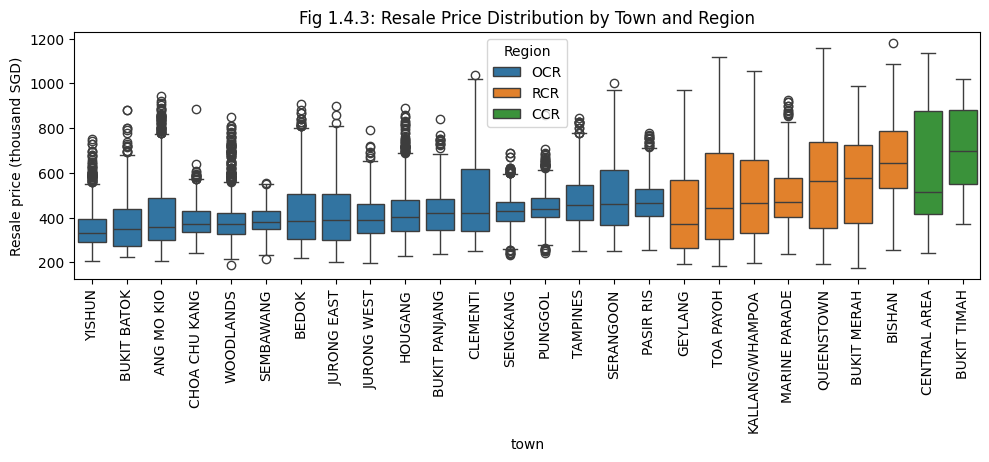

           town region     med
         YISHUN    OCR 330.000
    BUKIT BATOK    OCR 350.000
     ANG MO KIO    OCR 360.000
  CHOA CHU KANG    OCR 370.000
      WOODLANDS    OCR 370.000
      SEMBAWANG    OCR 380.000
          BEDOK    OCR 385.000
    JURONG EAST    OCR 389.000
    JURONG WEST    OCR 390.000
        HOUGANG    OCR 403.000
  BUKIT PANJANG    OCR 420.000
       CLEMENTI    OCR 420.000
       SENGKANG    OCR 428.000
        PUNGGOL    OCR 440.000
       TAMPINES    OCR 455.000
      SERANGOON    OCR 463.000
      PASIR RIS    OCR 465.000
        GEYLANG    RCR 370.000
      TOA PAYOH    RCR 445.000
KALLANG/WHAMPOA    RCR 465.000
  MARINE PARADE    RCR 469.000
     QUEENSTOWN    RCR 565.000
    BUKIT MERAH    RCR 579.000
         BISHAN    RCR 645.694
   CENTRAL AREA    CCR 514.000
    BUKIT TIMAH    CCR 698.000


In [10]:
# median price per town, plus its region
town_stats = (df_train.groupby('town')
              .agg(region=('region', 'first'), med=('price_k', 'median'))
              .reset_index())

# order regions as you like, then sort towns by median within each region
region_rank = {'OCR': 0, 'RCR': 1, 'CCR': 2}
town_stats['rank'] = town_stats['region'].map(region_rank)
order = town_stats.sort_values(['rank', 'med'])['town']

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_train, x='town', y='price_k', order=order,
            hue='region', dodge=False, palette='tab10')
plt.xticks(rotation=90)
plt.ylabel('Resale price (thousand SGD)')
plt.legend(title='Region')
plt.tight_layout();
plt.title('Fig 1.4.3: Resale Price Distribution by Town and Region')
plt.show()
print(town_stats.sort_values(['rank', 'med'])[['town', 'region', 'med']].to_string(index=False))

#### 1.4.4 Quick check of association between floor_area_sqm & flat_type ####

***Comments***
1. Quite strong associated relationship between floor_area_sqm & flat_type, will need to check multicollinearity after fitting M0

Text(0.5, 1.0, 'Fig 1.4.4: Flat Type VS Floor Area')

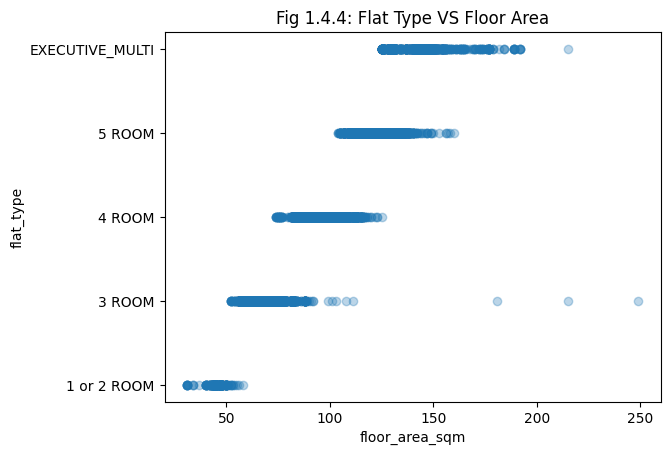

In [11]:
plt.scatter(df_train['floor_area_sqm'], df_train['flat_type'], alpha=0.3)
plt.xlabel('floor_area_sqm')
plt.ylabel('flat_type')
plt.title('Fig 1.4.4: Flat Type VS Floor Area')

## Part 2: M0 Modelling

A simple additive model on the raw scale using 6 regressors (area, lease, storey, flat type, region, model group):
$$\text{price\_k} \sim \text{area} + \text{lease} + \text{storey} + \text{ftype} + \text{region} + \text{model\_grp}$$
Region (CCR/RCR/OCR) is deliberately the coarsest location variable, so that model selection can show whether finer location matters. 
Baselines: flat type = 1-2 ROOM, region = CCR, flat-model tier = Basic.

***Significance Check*** (significance level $\alpha$ = 0.05)

1. The overall F-test is significant (F = 5390, p < 0.001). $R^2 = R^2_{adj} = 0.759$, so about 76% of the variation in price is explained, leaving room for improvement.
2. `region`, `flat_model_grouped`, `lease_years`, `floor_area_sqm` and `storey` are significant (p < 0.05) in both the t-tests and the partial F-tests.
3. `flat_type` is significant as a whole (partial F-test, F = 21.2, p < 0.001), but its individual coefficients are mixed: 5-ROOM is not significant (p = 0.356) and 4-ROOM is only marginal (p = 0.037).

***Problems:***

**A.Coefficient**

1. `flat_type`: the coefficients decrease as flat size increases (3-ROOM +20.4k, 4-ROOM +13.0k, 5-ROOM +6.8k, EXECUTIVE −27.4k, relative to 1-2 ROOM). This is implausible, since at the same floor area, lease and storey a larger flat type would not be expected to sell for less.
    - Likely cause: flat type is strongly associated with `floor_area`, so it adds little information once area is in the model (multicollinearity).
    - Approach: confirm with VIF, then consider dropping `flat_type` and compare the models with and without it.
2. `flat_model`: the Mainstream coefficient is negative relative to Basic (−36.8k), although Mainstream has higher raw prices.
    - Potential cause: Mainstream flats are larger(mean area: 99.1 vs 79), have longer leases(mean_lease: 77.9 vs 64.5) than Basic flats, so the model attributes their higher prices to `floor_area_sqm`, `lease_years` rather than to the tier (association between flat model and these regressors). The coarse region variable may also contribute.
    - Approach: check VIF for the flat-model dummies; refit with town-level effects (and log price) and track how the coefficient changes.

**B.Potential Multicollinearity**

1. The condition number is 3.33e+03, above the rule-of-thumb value of 1000, which warns of possible multicollinearity. It is sensitive to the scale of the variables, so this is confirmed with VIF in the adequacy checks.

In [12]:
prof = (df_train.groupby('flat_model_grouped')
        .agg(n=('price_k', 'size'),
             median_price=('price_k', 'median'),
             mean_area=('floor_area_sqm', 'mean'),
             mean_lease=('lease_years', 'mean'),
             mean_storey=('storey', 'mean'))
        .round(1))
print(prof)

                        n  median_price  mean_area  mean_lease  mean_storey
flat_model_grouped                                                         
Basic                4881         328.0       79.0        64.5          6.8
Executive            1482         620.0      145.2        74.5          7.4
Mainstream          13763         420.0       99.1        77.9          9.2
Unique                383         835.0      105.5        91.6         17.9


In [13]:
M0 = smf.ols('price_k ~ floor_area_sqm + lease_years + storey + C(flat_type) + C(region) + C(flat_model_grouped)', data=df_train).fit()
print(M0.summary())
print(sm.stats.anova_lm(M0, typ=2).round(2))



                            OLS Regression Results                            
Dep. Variable:                price_k   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     5390.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:35:44   Log-Likelihood:            -1.1714e+05
No. Observations:               20509   AIC:                         2.343e+05
Df Residuals:                   20496   BIC:                         2.344e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

### Part 2.1: Model Adequacy Checking

| Diagnostic | Comments | Suggested treatment |
|---|---|---|
| QQ plot of SR | The upper tail departs above the reference line (right-skewed residuals), indicating that the normality assumption is violated. | Box-Cox. |
| SR vs fitted | 1. The spread of SR increases with the fitted value (funnel shape), indicating non-constant variance. 2. 223 observations (1.1%) have \|SR\| > 3. No observation has Cook's distance above 1 (maximum = **0.037**), so none is influential, and these observations are retained. The excess of large residuals is consistent with the right-skewed errors and non-constant variance noted above, and is re-examined after the transformation. | 1. Transformation of y. |
| SR vs floor_area_sqm | The spread of SR changes across floor area (double-bow shape), indicating non-constant variance. | Transformation of y. |
----

**Multicollinearity** (VIF above 10 taken as a warning; the largest category is used as the baseline for each categorical variable)

1. `floor_area_sqm` has VIF = 12.2 (> 10), and the Executive dummies for `flat_type` (7.9) and `flat_model_grouped` (6.0) exceed 5. The other regressors, including `region`, `lease_years` and `storey`, are below 5. This indicates that floor area, flat type and the Executive tier all reflect flat size.
    - Approach: resolve through model selection first (e.g. dropping `flat_type`); consider Ridge regression only if multicollinearity persists in the selected model.


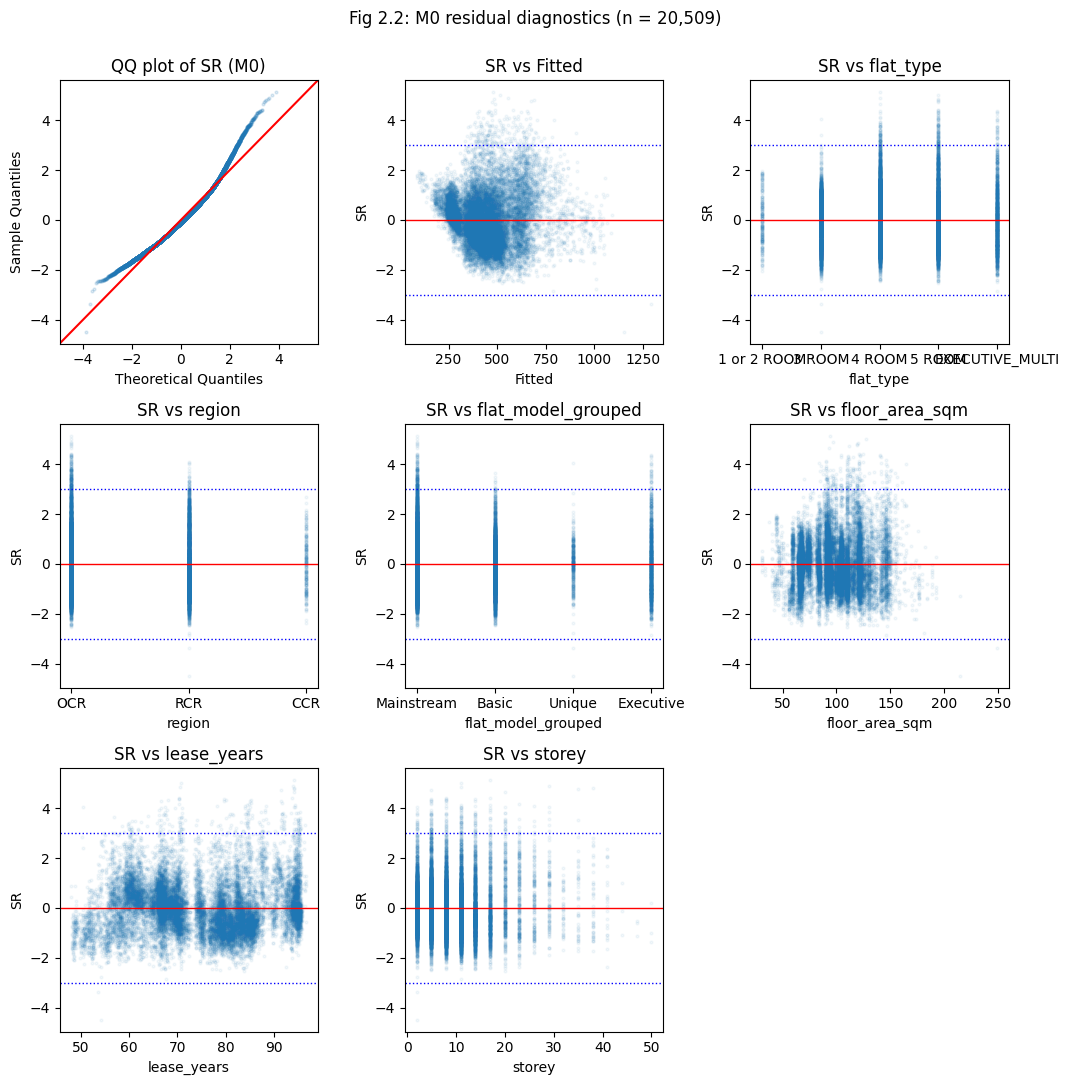

no. |SR|>3: 223
0
0.037695521727479


In [14]:
sr_M0 = SR(M0)

resid_plots(M0, df_train, ['flat_type', 'region', 'flat_model_grouped', 'floor_area_sqm', 'lease_years', 'storey'],
            title="M0", fig_label="Fig 2.2")

##Check number of outliers 
print("no. |SR|>3:", np.sum(np.abs(sr_M0) > 3))

cooks = M0.get_influence().cooks_distance[0]
print((cooks > 1).sum())  
print(max(cooks))

In [15]:
pd.set_option('display.max_colwidth', None)    # never truncate cell text

M0_vif_test = smf.ols('price_k ~ floor_area_sqm + lease_years + storey '
             '+ C(flat_type, Treatment("4 ROOM")) '
             '+ C(region, Treatment("OCR")) '
             '+ C(flat_model_grouped, Treatment("Mainstream"))', data=df_train).fit()
vif_table(M0_vif_test)


,variable,VIF
10,floor_area_sqm,12.16
4,"C(flat_type, Treatment(""4 ROOM""))[T.EXECUTIVE_MULTI]",7.86
8,"C(flat_model_grouped, Treatment(""Mainstream""))[T.Executive]",6.03
2,"C(flat_type, Treatment(""4 ROOM""))[T.3 ROOM]",4.68
3,"C(flat_type, Treatment(""4 ROOM""))[T.5 ROOM]",3.00
11,lease_years,2.04
7,"C(flat_model_grouped, Treatment(""Mainstream""))[T.Basic]",1.66
1,"C(flat_type, Treatment(""4 ROOM""))[T.1 or 2 ROOM]",1.63
6,"C(region, Treatment(""OCR""))[T.RCR]",1.22
12,storey,1.20


### Part 2.3: Transformation of the response (Box-Cox)

The residual plots of M0 show a funnel shape and right-skewed residuals, so a transformation of the response is considered. The Box-Cox profile (Fig 2.3) is minimised at $\hat\lambda \approx -0.392$ (95% CI: −0.432 to −0.372). λ = 1 (no transformation) lies far outside the interval, so a transformation is needed.

| λ | Transformation | $SS_{Res}$ (millions) |
|---|---|---|
| 1 | none | 109.8 |
| 0 | log | 80.7 |
| −0.5 | 1/√y | 78.7 |
| −1 | 1/y | 83.4 |

The interval does not contain λ = 0, but with n = 20,509 it is very narrow, so even small departures from the optimum are detectable. Among interpretable candidates, log has a clearly lower $SS_{Res}$ than the reciprocal and is only slightly above the minimum, and its coefficients are interpretable as approximate percentage changes in price. We therefore use $\log(\text{price\_k})$ as the response in the subsequent models.

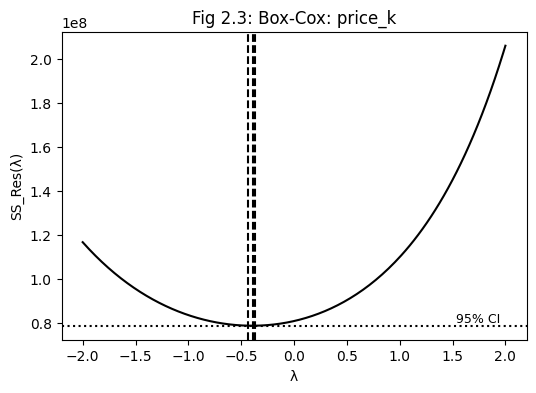

best λ = -0.392
95% CI crossings ≈ [-0.432 -0.372]
-1 83.38
-0.5 78.7
0 80.68
0.5 90.17
1 109.77


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2

def boxcox_ss_plot(model, lam_range=(-2, 2), n_lam=200, alpha=0.05,
                   title="Box-Cox", ax=None):
    """model: fitted OLS on the ORIGINAL y (y must be > 0).
    Plots SS_Res(lambda) against lambda, with the (1-alpha) confidence interval for lambda."""
    X = model.model.exog
    y = model.model.endog
    n = len(y)
    if np.any(y <= 0):
        raise ValueError("Box-Cox needs y > 0")

    lambdas = np.linspace(lam_range[0], lam_range[1], n_lam)
    gm = np.exp(np.mean(np.log(y)))                    # geometric mean of y

    ss = []
    for lam in lambdas:
        if abs(lam) > 1e-8:
            z = (y**lam - 1) / (lam * gm**(lam - 1))   # scaled so SS_Res is comparable across lambda
        else:
            z = gm * np.log(y)
        ss.append(sm.OLS(z, X).fit().ssr)
    ss = np.array(ss)

    best = lambdas[np.argmin(ss)]
    thresh = ss.min() * np.exp(chi2.ppf(1 - alpha, df=1) / n)   # SS* for the CI
    ci = lambdas[np.where(np.diff(np.sign(ss - thresh)))[0]]

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    ax.plot(lambdas, ss, c="black")
    ax.axhline(thresh, c="black", ls="dotted")
    ax.axvline(best, c="black", ls="dashed")
    for c in ci:
        ax.axvline(c, c="black", ls="dashed")
    ax.set_xlabel("λ"); ax.set_ylabel("SS_Res(λ)")
    ax.set_title(title)
    ax.text(lam_range[1] - 0.05, thresh, f"{int((1-alpha)*100)}% CI", fontsize=9,
            ha="right", va="bottom")
    plt.show()

    print(f"best λ = {best:.3f}")
    print(f"{int((1-alpha)*100)}% CI crossings ≈ {np.round(ci, 3)}")
    return best, ci, lambdas, ss

def boxcox_ssres(model, lam):
    X = model.model.exog
    y = model.model.endog
    gm = np.exp(np.mean(np.log(y)))
    z = (y**lam - 1) / (lam * gm**(lam - 1)) if abs(lam) > 1e-8 else gm * np.log(y)
    return sm.OLS(z, X).fit().ssr



best, ci, lam, ss = boxcox_ss_plot(M0, title="Fig 2.3: Box-Cox: price_k")
for l in [-1, -0.5, 0, 0.5, 1]:
    print(l, round(boxcox_ssres(M0, l) / 1e6, 2))

## Part 2.4: Model M1: $\log(\text{price\_k})$ response

**Model.** $\log(\text{price\_k}) \sim \text{flat\_type} + \text{region} + \text{flat\_model\_grouped} + \text{floor\_area\_sqm} + \text{lease\_years} + \text{storey}$

M0 showed a funnel in the SR vs fitted plot and strong right skew in the QQ plot. M1 keeps the same regressors but changes the response to $\log(\text{price\_k})$ to correct these problems.

### 1. Significance check

**Overall.** The F-test gives F = 5807 (p ≈ 0), so at least one regressor is significantly related to $\log(\text{price\_k})$. $R^2 = R^2_{adj} = 0.773$, and the residual standard error is 0.149, i.e. a typical prediction error of about 15%. The RSE cannot be compared with M0's, because it is in log units whereas M0's is in thousand SGD. $R^2$ is unit-free, so 0.759 (M0) and 0.773 (M1) can be read side by side as a rough guide, but they measure the variation of different responses. 

**Individual t-tests.** All coefficients have p < 0.05 (M0 had one insignificant coefficient).

**Partial F-tests (Type II ANOVA).** Every term has p < 0.05, so all regressors are significant after adjusting for the others. The terms ranked by F are region (5947), floor_area_sqm (3345), storey (2643), lease_years (2200), flat_model_grouped (546) and flat_type (104).

**Interpretation.** Since the response is in logs, a coefficient $b$ multiplies the price by $e^{b}$, holding the other regressors fixed. Each extra sqm of floor area raises price by about 0.9%, each extra year of lease by 0.6%, and each extra floor by 1.0%. Relative to CCR, OCR flats are about 34% cheaper and RCR flats about 11% cheaper. Relative to Basic, Unique flats are about 21% more expensive and Executive flats about 5% more expensive.

**Unreasonable coefficients.** Two issues remain.
- The flat_type effects are not monotone. Relative to 1 or 2 ROOM, 4 ROOM is +21% but 5 ROOM is only +19%, and EXECUTIVE_MULTI (+12%) is lower than 3 ROOM (+16%). Larger flat types should not be cheaper once area is fixed. This is probably because floor area already carries most of the size information.
- Mainstream is still negative relative to Basic (−6%). This is probably because region is too coarse and town effects are missing.

### 2. Model adequacy checking

**Normality.** In M0, the QQ plot bends upward at both ends: the upper tail is heavier and the lower tail lighter than a normal distribution, indicating right skew. In M1 the tails are much closer to the line (SR roughly between −3 and 4), and skewness falls from 0.76 in M0 to 0.39. A mild right skew remains. Since the sample is large (n = 20,509) and the departure is mild, the inference results are considered reliable, so no further transformation is applied.

**Constant variance.** In M0 the spread of SR widened with the fitted price (funnel shape). In M1 the funnel has disappeared, and only a mild double-bow remains. To quantify this, the observations were sorted by fitted value and divided into ten equal-sized groups, and the standard deviation of SR was computed in each group (Table below). Since SR has unit variance by construction, values close to 1 indicate constant spread.

***Table: SD of SR of M1***

| Decile | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| SD of SR | 0.73 | 0.95 | 1.08 | 1.01 | 1.03 | 1.04 | 1.00 | 1.03 | 1.03 | 0.94 |

For M0 on the raw scale, the SD rises from 0.48 to 1.26 across the deciles. After the log transformation, the SD lies between 0.94 and 1.08 in nine of the ten groups, and only the lowest decile is clearly lower (0.73). The remaining patterns (the mild double-bow and a slight downward drift at high fitted values) are small and are consistent with missing location and curvature terms.

**SR vs regressors.** 
- The residuals are centred at 0 with similar spread for flat_type, region, flat_model_grouped and floor_area_sqm. 
- There is slight curvature in storey above about 20 floors. 


**Outliers.** 
129 observations with |SR| > 3 (M0 had 223), and max Cook's D = 0.058 . No Cook's D exceeds 1, there are no influential points, so the observations are kept.

### 3. Summary

**Improved from M0 to M1:**
- Non-constant variance is largely resolved.
- Normality is improved to a mild departure.
- All coefficients are now significant.

**Remaining problems:**
- Unreasonable flat_type and Mainstream coefficients.
- Multicollinearity. The condition number is 3.33e+03, which suggests flat_type overlaps with floor_area_sqm. This will be examined with VIF and dealt with later through model selection (e.g. comparing models with and without flat_type), and by ridge regression only if the problem persists.

In [17]:
M1 = smf.ols('np.log(price_k) ~ floor_area_sqm + lease_years + storey + C(flat_type) + C(region) + C(flat_model_grouped)', data=df_train).fit()
print(M1.summary())
print(sm.stats.anova_lm(M1, typ=2).round(2))

                            OLS Regression Results                            
Dep. Variable:        np.log(price_k)   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     5807.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:35:46   Log-Likelihood:                 9996.8
No. Observations:               20509   AIC:                        -1.997e+04
Df Residuals:                   20496   BIC:                        -1.986e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

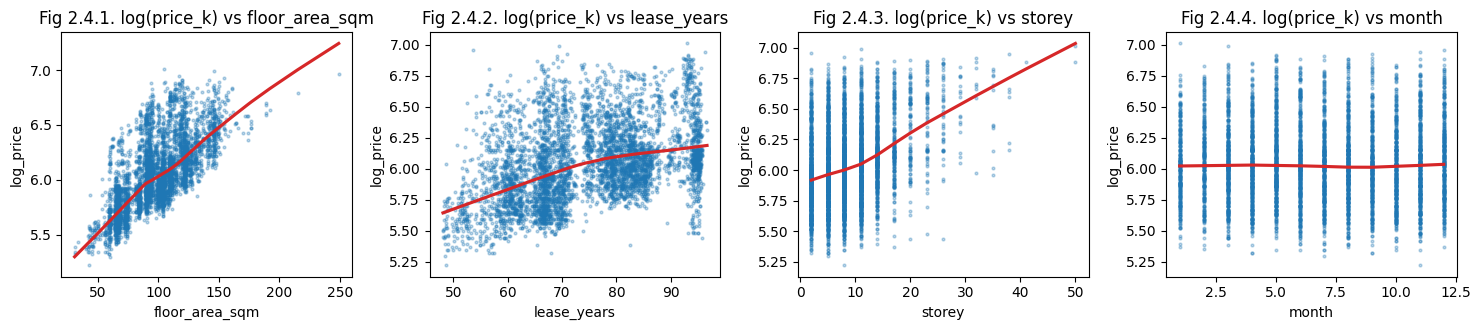

                log_price  floor_area_sqm  lease_years  storey  month
log_price            1.00            0.69         0.40    0.37   0.01
floor_area_sqm       0.69            1.00         0.30    0.05   0.03
lease_years          0.40            0.30         1.00    0.30   0.02
storey               0.37            0.05         0.30    1.00   0.03
month                0.01            0.03         0.02    0.03   1.00


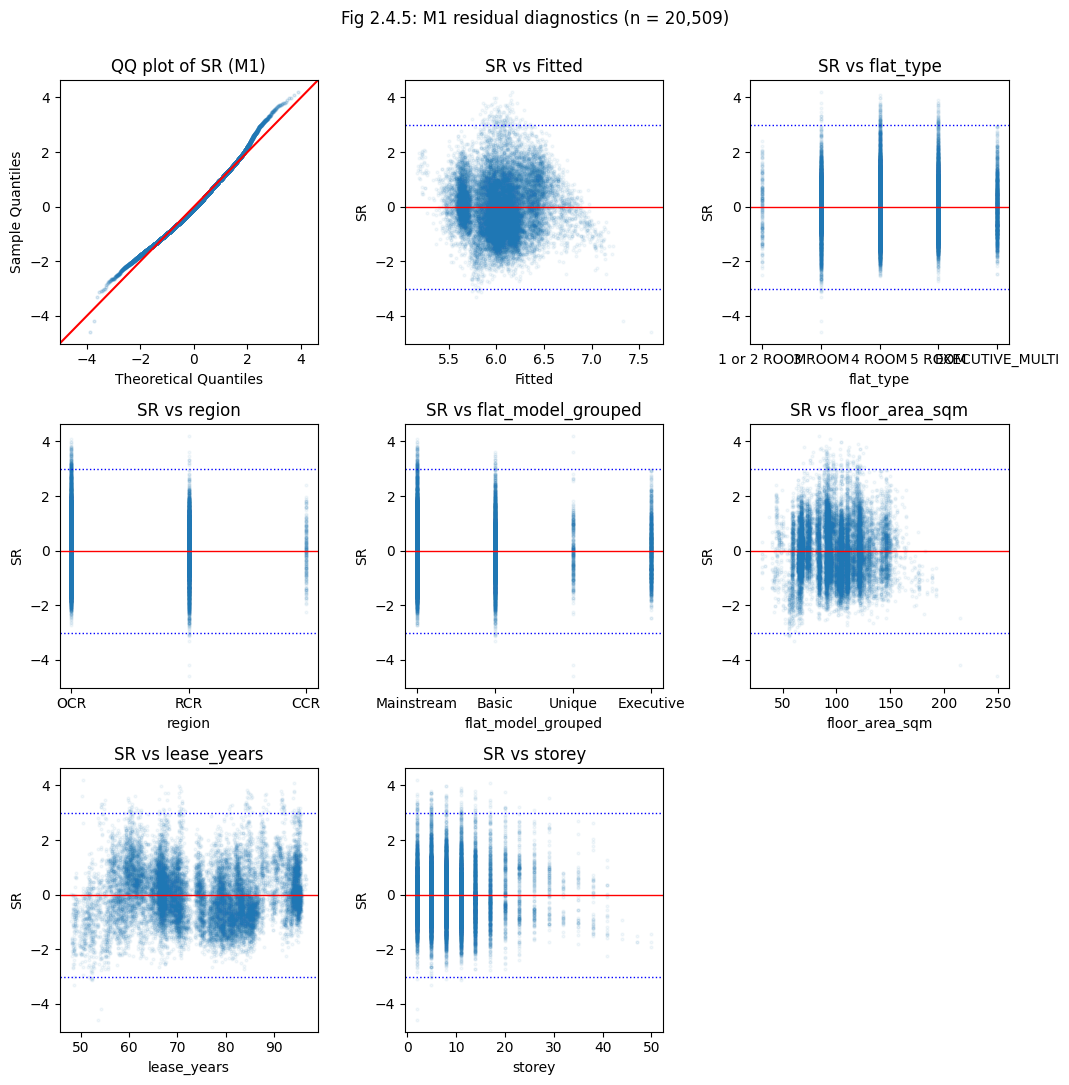

no. |SR|>3: 129
0
0.05814136379342044


In [18]:
sr_M1 = SR(M1)

s = df_train.sample(5000, random_state=1)
s = s.copy()
s['log_price'] = np.log(s['price_k'])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, v in zip(ax, ['floor_area_sqm','lease_years','storey', 'month']):
    sns.regplot(data=s, x=v, y='log_price', ax=a, scatter_kws=dict(s=4, alpha=.3), lowess=True, line_kws=dict(color='C3'))
    a.set_title(f'Fig 2.4.{ax.tolist().index(a)+1}. log(price_k) vs {v}')
plt.tight_layout(); plt.show()
print(df_train[['log_price','floor_area_sqm','lease_years','storey','month']].corr().round(2))


resid_plots(M1, df_train, ['flat_type', 'region', 'flat_model_grouped', 'floor_area_sqm', 'lease_years', 'storey'],
            title="M1", fig_label="Fig 2.4.5")

##Check number of outliers 
print("no. |SR|>3:", np.sum(np.abs(sr_M1) > 3))


cooks = M1.get_influence().cooks_distance[0]
print((cooks > 1).sum())  
print(max(cooks))

In [19]:
sr = pd.Series(SR(M1), index=M1.fittedvalues.index)
q = pd.qcut(M1.fittedvalues, 10, labels=False) + 1
tbl = sr.groupby(q).std().round(2)
print(tbl)
sr_m0 = pd.Series(SR(M0), index=M1.fittedvalues.index)
q_m0 = pd.qcut(M0.fittedvalues, 10, labels=False) + 1
tbl_m0 = sr_m0.groupby(q_m0).std().round(2)
print(tbl_m0)


1     0.73
2     0.95
3     1.08
4     1.01
5     1.03
6     1.04
7     1.00
8     1.03
9     1.03
10    0.94
dtype: float64
1     0.48
2     0.68
3     0.87
4     0.87
5     0.91
6     0.97
7     1.01
8     1.07
9     1.24
10    1.26
dtype: float64


## Part 2.5: Model M2: town replaces region

**Model.** $\log(\text{price\_k}) \sim \text{flat\_type} + \text{town} + \text{flat\_model\_grouped} + \text{floor\_area\_sqm} + \text{lease\_years} + \text{storey}$

The M1 diagnostics showed three signs that region is too coarse. Mainstream remains negative relative to Basic. Prices also vary widely within each region: median prices in OCR range from 330k (Yishun) to 465k (Pasir Ris), and in RCR from 370k (Geylang) to 646k (Bishan). Therefore region is replaced by the 26 towns. Town is a finer location variable, and it already contains the information in region, so region is dropped. The cost is more parameters, but with n = 20,509 each town still has enough observations.

**Overall.** The F-test gives F = 4465 (p ≈ 0), so at least one regressor is significantly related to $\log(\text{price\_k})$. $R^2 = R^2_{adj} = 0.884$, and the residual standard error is 0.106, i.e. a typical prediction error of about 11%.

### 1. Significance check

**Region vs town.** Replacing region with town raises $R^2_{adj}$ from 0.773 to 0.884 and lowers the residual standard error from 0.149 to 0.106. Since both models have the same response, these values are directly comparable, so town fits clearly better.

**Individual t-tests.** All coefficients have p < 0.001.

**Partial F-tests (Type II ANOVA).** Every term is significant. By F: lease_years (7202), floor_area_sqm (4915), storey (3000), town (1720), flat_model_grouped (297), flat_type (218).

**Interpretation.** The baselines are 1 or 2 ROOM, ANG MO KIO and Basic. Since the response is in logs, a coefficient $b$ multiplies the price by $e^{b}$, holding the other regressors fixed.
- Each extra sqm of floor area raises price by about 0.8%, each extra year of lease by about 0.9%, and each extra floor by about 0.8%.
- Town: relative to Ang Mo Kio, Marine Parade (+38%) and Bukit Timah (+36%) are the most expensive. Sembawang (−32%), Choa Chu Kang (−32%) and Woodlands (−30%) are the cheapest.
- Flat type: 3 ROOM +16%, 4 ROOM +25%, 5 ROOM +26% and EXECUTIVE_MULTI +26%.
- Flat model group (vs Basic): Unique +16%, Executive +6%, Mainstream −2%.

**Problems resolved from M1.**
- The flat_type coefficients now increase with flat size, as expected, instead of being unordered.
- The Mainstream coefficient shrinks from −6% to −2%. It is still slightly negative, but small enough not to affect the interpretation.

### 2. Model adequacy checking

**Normality.** 
The QQ plot lies close to the line over almost the whole range. The right skew of M0 and M1 is mostly gone, and skewness falls from 0.39 (M1) to 0.28 (M2). Only a few points in the upper tail depart from the line, and these are examined under outliers below.

**Constant variance.** 
The SR vs fitted plot shows no funnel. The spread looks narrower at both ends, but there are few observations there, so the cloud appears thinner. To check this, the standard deviation of SR was computed in ten equal-sized groups of fitted values (Table below).

| Decile | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| SD of SR | 0.91 | 0.91 | 0.89 | 0.96 | 1.06 | 0.92 | 0.99 | 1.14 | 1.11 | 0.95 |

All ten values lie between 0.89 and 1.14, close to 1 (M1: 0.73 to 1.08, M0:0.48 to 1.26). The variance is therefore treated as constant, and no weighted least squares is needed.

**Linearity and other regressors.** 
SR vs town is now centred at 0 in every town, as expected with town in the model. 
For SR vs lease_years, the large positive and negative blocks seen in M1 are smaller, so part of the wave came from price differences between towns. However, a smaller wave remains (slightly positive around 66–67 years and slightly negative around 78–86 years), which suggests the effect of lease differs between towns.

**Outliers and influential points.** 
86 observations (0.42%) have |SR| > 3, compared with 223 in M0. 
Under normality about 0.27% would be expected, so this is slightly higher, consistent with the small remaining right skew. The maximum Cook's D is 0.016, far below 1, so there are no influential points. These observations are outliers in y but not influential, so they are kept.

**Conclusion.** The assumptions of normality and constant variance are acceptable for M2, and the model is adequate.

### 3. Improvements from M1 to M2
- Location is captured at town level: $R^2_{adj}$ rises from 0.773 to 0.884, and the residual standard error falls from 0.149 to 0.106.
- The flat_type and Mainstream coefficients are now reasonable.
- Normality is further improved.

### 4. Remaining issues
- The condition number is 3.50e+03. Multicollinearity will be checked with VIF in the next step and dealt with in model selection (with and without flat_type).
- The faint wave in SR vs lease_years may indicate that the lease effect differs by town. 


                            OLS Regression Results                            
Dep. Variable:        np.log(price_k)   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     4465.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:35:47   Log-Likelihood:                 16908.
No. Observations:               20509   AIC:                        -3.374e+04
Df Residuals:                   20473   BIC:                        -3.346e+04
Df Model:                          35                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

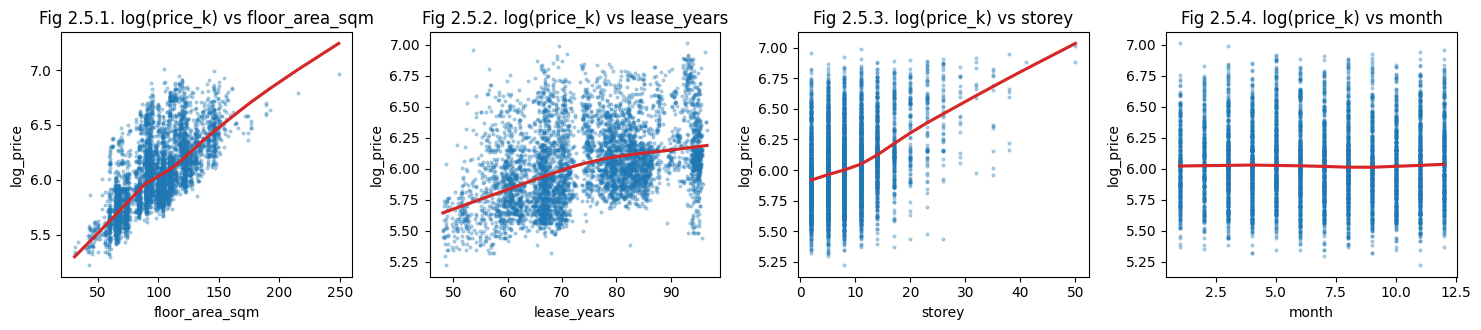

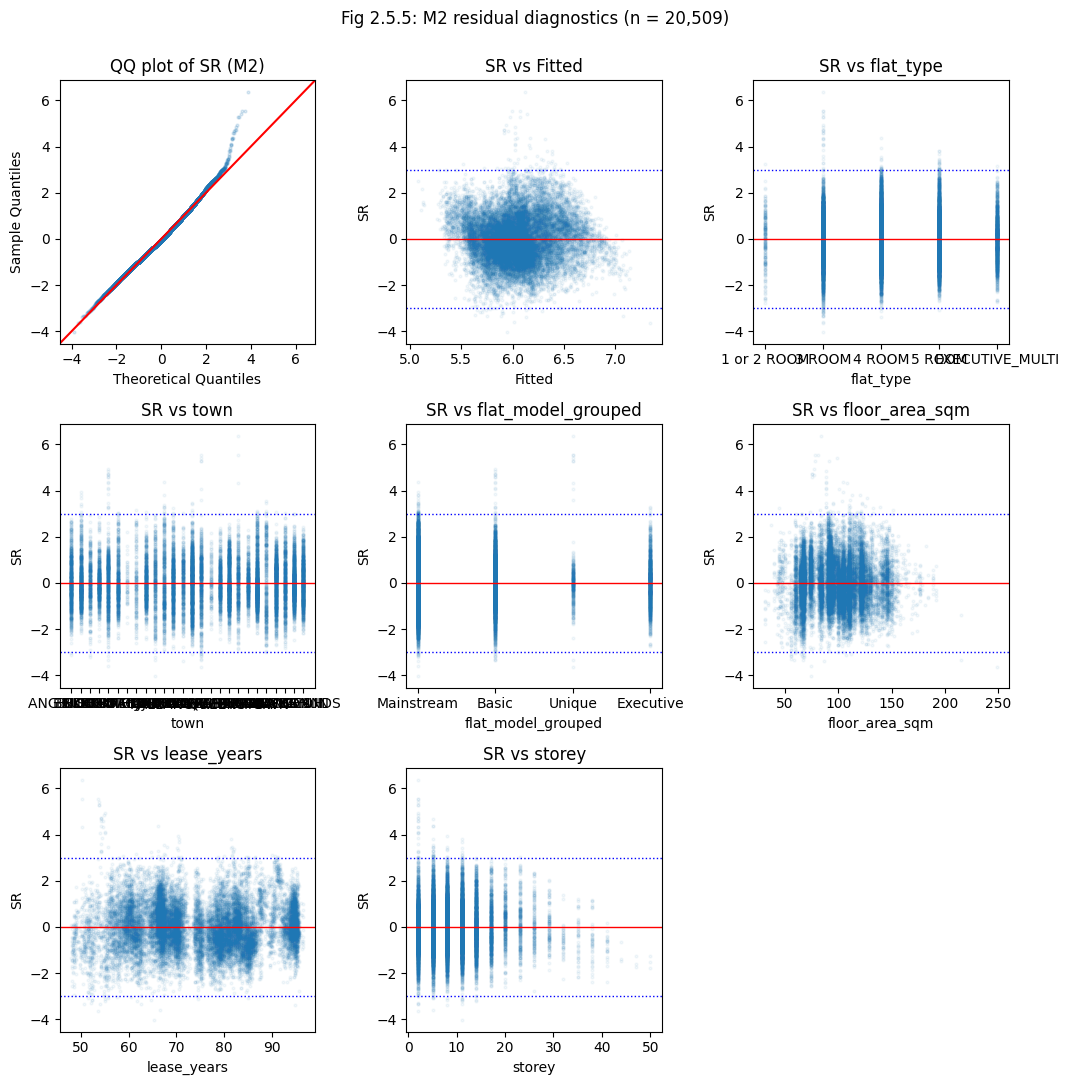

no. |SR|>3: 86
cooks > 1 number : 0
max cooks : 0.01602899505081682
1     0.91
2     0.91
3     0.89
4     0.96
5     1.06
6     0.92
7     0.99
8     1.14
9     1.11
10    0.95
dtype: float64


In [20]:
M2 = smf.ols('np.log(price_k) ~ floor_area_sqm + lease_years + storey + C(flat_type) + C(town) + C(flat_model_grouped)', data=df_train).fit()
print(M2.summary())
print(sm.stats.anova_lm(M2, typ=2).round(2))

sr_M2 = SR(M2)

s = df_train.sample(5000, random_state=1)
s = s.copy()
s['log_price'] = np.log(s['price_k'])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, v in zip(ax, ['floor_area_sqm','lease_years','storey', 'month']):
    sns.regplot(data=s, x=v, y='log_price', ax=a, scatter_kws=dict(s=4, alpha=.3), lowess=True, line_kws=dict(color='C3'))
    a.set_title(f'Fig 2.5.{ax.tolist().index(a)+1}. log(price_k) vs {v}')
plt.tight_layout(); plt.show()
# print(df_train[['log_price','floor_area_sqm','lease_years','storey','month']].corr().round(2))


resid_plots(M2, df_train, ['flat_type', 'town', 'flat_model_grouped', 'floor_area_sqm', 'lease_years', 'storey'],
            title="M2", fig_label="Fig 2.5.5")

##Check number of outliers 
print("no. |SR|>3:", np.sum(np.abs(sr_M2) > 3))

cooks = M2.get_influence().cooks_distance[0]
print(f'cooks > 1 number : {(cooks > 1).sum()}')  
print(f'max cooks : {max(cooks)}')


sr2 = pd.Series(SR(M2), index=M2.fittedvalues.index)
q = pd.qcut(M2.fittedvalues, 10, labels=False) + 1
print(sr2.groupby(q).std().round(2))

## Part 2.6: Model Selection

**Criteria.** Candidate models are compared by $R^2_{adj}$, the residual standard error (RSE), AIC, BIC and the maximum VIF.
- AIC = −2 log L + 2p; BIC = −2 log L + p ln n, where p is the number of parameters. Lower is better, and BIC penalises extra parameters more heavily.
- AIC, BIC and RSE are only comparable between models fitted to the same response and the same data. M0 (raw price) is therefore excluded: its log-likelihood is on the scale of price, so its AIC (2.343 × 10⁵) cannot be compared with M1's (−1.997 × 10⁴), and its RSE is in thousand SGD whereas M1's is in log units. The choice of log over raw price rests on the Box-Cox profile (Part 2.3) and the residual diagnostics, not on these criteria.
- The VIFs are computed with the largest category as the baseline of each categorical variable.

| Model | Parameters | $R^2_{adj}$ | RSE | AIC | BIC | Max VIF |
|---|---|---|---|---|---|---|
| M0 (raw price, region) | 13 | n/a | n/a | n/a | n/a | 12.16 |
| M1 (log, region) | 13 | 0.7726 | 0.1487 | −19968 | −19864 | 12.16 |
| M2 (log, town) | 36 | 0.8840 | 0.1062 | −33745 | −33459 | 13.65 |
| M3a (M2 without flat_type) | 32 | 0.8790 | 0.1084 | −32896 | −32642 | 2.30 |
| M3b (M2 without floor area) | 35 | 0.8561 | 0.1183 | −29333 | −29056 | 6.00 |
| M3 (M3a with √floor area) | 32 | 0.8838 | 0.1063 | −33714 | −33460 | 2.31 |

**Location (M1 → M2).** Replacing region with town improves every criterion (the $R^2_{adj}$ rises from 0.773 to 0.884, the RSE falls from 0.149 to 0.106, and AIC and BIC fall by more than 13,000), so town is kept.

**Multicollinearity in M2.** floor_area_sqm has a VIF of 13.65 (> 10), and the EXECUTIVE_MULTI and 3 ROOM dummies of flat_type (8.24, 4.99) and the Executive model group (6.08) also exceed 5, because flat_type is largely a size grouping of floor area. A high VIF does not by itself imply that a variable should be removed, so two candidates are compared.
- **M3b (drop floor_area_sqm)** is clearly worse ($R^2_{adj}$ 0.8561, AIC higher by 4,412) and still leaves VIFs above 5.
- **M3a (drop flat_type)** removes the multicollinearity (all VIF < 5), but costs some fit ($R^2_{adj}$ 0.8790, RSE 0.1084; AIC and BIC higher by 849 and 817). Part of the contribution of flat_type was therefore to absorb non-linearity in floor area.

**Square-root area (M3a → M3).** After removing flat_type, the residuals of M3a curve against floor area (Part 2.7, §2), so floor_area_sqm is replaced by its square root. This restores the fit of M2 with four fewer parameters: $R^2_{adj}$ = 0.8838 (M2: 0.8840), RSE = 0.1063 (M2: 0.1062), essentially the same BIC (−33460 vs −33459), and a maximum VIF of 2.31.

**Conclusion.** M3 has practically the same fit as M2 with a simpler structure and no multicollinearity, so M3 is selected. Since multicollinearity is resolved by selection, ridge regression is not needed.

**Backward check on M3.** Each remaining term of M3 is dropped in turn, and the model is refitted (Table below). The full M3 has $R^2_{adj}$ = 0.8838 and RSE = 0.1063.

| Term dropped | Partial F | $R^2_{adj}$ | Change in $R^2_{adj}$ | RSE | Change in AIC | Change in BIC |
|---|---|---|---|---|---|---|
| town | 1748.2 | 0.6361 | −0.2476 | 0.1880 | +23380 | +23182 |
| flat_model_grouped | 404.5 | 0.8769 | −0.0069 | 0.1094 | +1175 | +1151 |
| √floor_area_sqm | 47817.6 | 0.6124 | −0.2714 | 0.1941 | +24702 | +24694 |
| lease_years | 8806.8 | 0.8338 | −0.0500 | 0.1271 | +7335 | +7327 |
| storey | 3062.3 | 0.8664 | −0.0174 | 0.1140 | +2856 | +2848 |

Removing any term lowers $R^2_{adj}$, raises the RSE and increases both AIC and BIC, and every partial F-test is highly significant (p ≈ 0). The most important terms are √floor_area_sqm, town and lease_years, whose removal reduces $R^2_{adj}$ by 0.05 to 0.27. The least important term is flat_model_grouped: dropping it lowers $R^2_{adj}$ by only 0.007, but AIC and BIC still increase by more than 1,000, so it is kept. No term can be removed without a clear loss of fit, so M3 is the final model.

In [21]:
pd.set_option('display.max_colwidth', None)    # never truncate cell text

M2_vif_test = smf.ols('np.log(price_k) ~ floor_area_sqm + lease_years + storey '
             '+ C(flat_type, Treatment("4 ROOM")) '
             '+ C(town, Treatment("TAMPINES")) '
             '+ C(flat_model_grouped, Treatment("Mainstream"))', data=df_train).fit()


vif_table(M2_vif_test)

,variable,VIF
33,floor_area_sqm,13.65
4,"C(flat_type, Treatment(""4 ROOM""))[T.EXECUTIVE_MULTI]",8.24
31,"C(flat_model_grouped, Treatment(""Mainstream""))[T.Executive]",6.08
2,"C(flat_type, Treatment(""4 ROOM""))[T.3 ROOM]",4.99
3,"C(flat_type, Treatment(""4 ROOM""))[T.5 ROOM]",3.22
34,lease_years,2.63
25,"C(town, Treatment(""TAMPINES""))[T.SENGKANG]",2.37
22,"C(town, Treatment(""TAMPINES""))[T.PUNGGOL]",2.30
18,"C(town, Treatment(""TAMPINES""))[T.JURONG WEST]",2.14
28,"C(town, Treatment(""TAMPINES""))[T.WOODLANDS]",2.09


In [22]:
FT   = 'C(flat_type, Treatment("4 ROOM"))'
TOWN = 'C(town, Treatment("TAMPINES"))'
REG  = 'C(region, Treatment("OCR"))'
FM   = 'C(flat_model_grouped, Treatment("Mainstream"))'

cands = {
    "M0 (raw price, region)": f'price_k ~ {FT} + {REG} + {FM} + floor_area_sqm + lease_years + storey',
    "M1 (log, region)":       f'np.log(price_k) ~ {FT} + {REG} + {FM} + floor_area_sqm + lease_years + storey',
    "M2 (log, town)":         f'np.log(price_k) ~ {FT} + {TOWN} + {FM} + floor_area_sqm + lease_years + storey',
    "M3a (drop flat_type)":   f'np.log(price_k) ~ {TOWN} + {FM} + floor_area_sqm + lease_years + storey',
    "M3b (drop area)":        f'np.log(price_k) ~ {FT} + {TOWN} + {FM} + lease_years + storey',
    "M3 (sqrt area)":         f'np.log(price_k) ~ {TOWN} + {FM} + np.sqrt(floor_area_sqm) + lease_years + storey',
}

rows = []
for name, f in cands.items():
    m = smf.ols(f, data=df_train).fit()
    comparable = not name.startswith("M0")
    rows.append({
        "model": name,
        "n_params": int(m.df_model) + 1,
        "R2_adj": round(m.rsquared_adj, 4) if comparable else "n/a",
        "RSE": round(np.sqrt(m.scale), 4) if comparable else "n/a",
        "AIC": round(m.aic) if comparable else "n/a",
        "BIC": round(m.bic) if comparable else "n/a",
        "max_VIF": vif_table(m)["VIF"].max(),
    })
print(pd.DataFrame(rows).to_string(index=False))

# full VIF table of each candidate, highest first
# pd.set_option("display.max_colwidth", None)
# for name, m in models.items():
#     print("\n", name)
#     print(vif_table(m).sort_values("VIF", ascending=False).head(8).to_string(index=False))

                 model  n_params  R2_adj     RSE    AIC    BIC  max_VIF
M0 (raw price, region)        13     n/a     n/a    n/a    n/a    12.16
      M1 (log, region)        13  0.7726  0.1487 -19968 -19864    12.16
        M2 (log, town)        36   0.884  0.1062 -33745 -33459    13.65
  M3a (drop flat_type)        32   0.879  0.1084 -32896 -32642     2.30
       M3b (drop area)        35  0.8561  0.1183 -29333 -29056     6.00
        M3 (sqrt area)        32  0.8838  0.1063 -33714 -33460     2.31


In [23]:
full = smf.ols(cands["M3 (sqrt area)"], data=df_train).fit()
Ftab = sm.stats.anova_lm(full, typ=2)["F"]          # partial F of each term (tested last)

terms = {
    "town":               f'np.log(price_k) ~ {FM} + np.sqrt(floor_area_sqm) + lease_years + storey',
    "flat_model_grouped": f'np.log(price_k) ~ {TOWN} + np.sqrt(floor_area_sqm) + lease_years + storey',
    "sqrt(area)":         f'np.log(price_k) ~ {TOWN} + {FM} + lease_years + storey',
    "lease_years":        f'np.log(price_k) ~ {TOWN} + {FM} + np.sqrt(floor_area_sqm) + storey',
    "storey":             f'np.log(price_k) ~ {TOWN} + {FM} + np.sqrt(floor_area_sqm) + lease_years',
}
ftab_names = {"town": "C(town, Treatment(\"TAMPINES\"))",
              "flat_model_grouped": "C(flat_model_grouped, Treatment(\"Mainstream\"))",
              "sqrt(area)": "np.sqrt(floor_area_sqm)", "lease_years": "lease_years", "storey": "storey"}

rows = []
for t, f in terms.items():
    m = smf.ols(f, data=df_train).fit()
    rows.append({
        "dropped": t,
        "partial_F": round(Ftab[ftab_names[t]], 1),
        "R2_adj": round(m.rsquared_adj, 4),
        "RSE": round(np.sqrt(m.scale), 4),
        "dAIC": round(m.aic - full.aic),
        "dBIC": round(m.bic - full.bic),
    })
print(f"full M3: R2_adj = {full.rsquared_adj:.4f}, RSE = {np.sqrt(full.scale):.4f}")
print(pd.DataFrame(rows).to_string(index=False))

full M3: R2_adj = 0.8838, RSE = 0.1063
           dropped  partial_F  R2_adj    RSE  dAIC  dBIC
              town     1748.2  0.6361 0.1880 23380 23182
flat_model_grouped      404.5  0.8769 0.1094  1175  1151
        sqrt(area)    47817.6  0.6124 0.1941 24702 24694
       lease_years     8806.8  0.8338 0.1271  7335  7327
            storey     3062.3  0.8664 0.1140  2856  2848


## Part 2.7: Model M3: dropping flat_type and using $\sqrt{\text{floor\_area\_sqm}}$

**Model.** $\log(\text{price\_k}) \sim \text{town} + \text{flat\_model\_grouped} + \sqrt{\text{floor\_area\_sqm}} + \text{lease\_years} + \text{storey}$

M3 makes two changes to M2: flat_type is dropped to deal with multicollinearity, and floor_area_sqm is replaced by its square root to deal with curvature.

### 1. Dropping flat_type (multicollinearity)

The condition number of M2 is 3.50e+03, and the VIFs confirm the overlap: floor_area_sqm has a VIF of 13.65 (> 10), and the EXECUTIVE_MULTI and 3 ROOM dummies of flat_type (8.24, 4.99) and the Executive model group (6.08) exceed 5. The reason is that flat_type is largely a size grouping of floor area.

The comparison of the two candidate fixes is in Part 2.6. In short, dropping floor_area_sqm (M3b) worsens the fit clearly ($R^2_{adj}$ 0.8561) and leaves VIFs above 5, while dropping flat_type (M3a) removes the problem (max VIF 2.30) for a loss of only 0.5 percentage points of $R^2_{adj}$ (0.8790 vs 0.8840). Floor area is also the more informative variable, since flat_type is a coarse version of it. Although flat_type was significant in M2 (partial F = 218), its information is mostly contained in floor area, so it is removed for stability and simplicity.

### 2. Square-root transformation of floor area

After removing flat_type, SR vs floor_area_sqm of M3a (linear area) shows slight curvature: 
    - the residuals are mostly positive for flats of around 85–95 sqm and negative for the very large flats (above about 200 sqm, SR down to about −5 to −6), so the linear term does not fully capture the effect of area. 
    - A square root allows the effect of an extra sqm to decrease with size, so floor_area_sqm is replaced by $\sqrt{\text{floor\_area\_sqm}}$.

- M3a (linear area): $R^2_{adj}$ = 0.879, RSE = 0.1084.
- M3 (square-root area): $R^2_{adj}$ = 0.884, RSE = 0.1063.

The square-root form removes the extreme negative residuals (lowest SR about −4, QQ plot of SR of M3, square-root area) and recovers the fit of M2 ($R^2_{adj}$ = 0.884, RSE = 0.1062) with four fewer parameters. The sign of the Executive model group also becomes positive as expected (it was slightly negative with linear area), a further sign that the linear form was misspecified.

### 3. Multicollinearity check

After the transformation, all VIFs of M3 are below 3 (maximum 2.97 for the Sengkang dummy; $\sqrt{\text{floor\_area\_sqm}}$: 1.95, lease_years: 2.31, storey: 1.25), well below the rule-of-thumb threshold of 10 (M2 maximum: 13.65). Multicollinearity is therefore resolved, and ridge regression is not needed. The condition number (2.00e+03) is still flagged by the software, but it depends on the scale of the regressors, so the VIFs are used as the main check.

### 4. Significance check

**Overall.** F = 5031 (p ≈ 0), $R^2_{adj}$ = 0.884, and RSE = 0.1063 (typical error about 11%).

**Individual t-tests.** All coefficients have p < 0.05 (the weakest is Serangoon, p = 0.038).

**Partial F-tests (Type II ANOVA).** Every term is significant. By F: $\sqrt{\text{floor\_area\_sqm}}$ (47,818), lease_years (8,807), storey (3,062), town (1,748), flat_model_grouped (405).

**Interpretation.** Since the response is in logs, a coefficient $b$ multiplies the price by $e^{b}$, holding the other regressors fixed. The baselines are ANG MO KIO and Basic.
- Each extra year of lease raises price by about 0.9%, and each extra floor by about 0.8%.
- Because of the square root, the effect of area is not constant per sqm. With a coefficient of 0.1857, going from 70 sqm to 100 sqm raises price by a factor of $\exp(0.1857 \times (\sqrt{100}-\sqrt{70})) \approx 1.35$ (+35%). An extra sqm adds more in a small flat than in a large flat (diminishing returns).
- Flat model group (vs Basic): Unique +14%, Executive +4%, Mainstream −3%.
- Town (vs Ang Mo Kio): Marine Parade (+40%) and Bukit Timah (+37%) are the most expensive. Sembawang (−31%), Choa Chu Kang (−31%) and Woodlands (−30%) are the cheapest.

### 5. Model adequacy checking

**Normality.** The QQ plot follows the line closely over almost the whole range, including the lower tail. Skewness is 0.27 (M0: 0.76, M1: 0.39). Only a few points in the upper tail depart from the line, and these are examined under outliers below. The departure from normality is mild and acceptable.

**Constant variance.** The SR vs fitted plot shows no funnel and no drift at high fitted values. To quantify this, the standard deviation of SR was computed in ten equal-sized groups of fitted values (Table below).

| Decile | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| SD of SR | 0.91 | 0.88 | 0.89 | 0.98 | 1.04 | 0.95 | 1.00 | 1.16 | 1.12 | 0.95 |

All ten values lie between 0.88 and 1.16, close to 1 (M0: 0.48 to 1.26). The variance is treated as constant, so weighted least squares is not needed.

**Linearity and other regressors.** The residuals are centred at 0 for every town, every flat model group, and across floor area and storey, with no systematic pattern. A faint wave remains in SR vs lease_years, much smaller than in M1, and a slight downward drift in storey above about 25 floors, where observations are few.

**Outliers and influential points.** 87 observations (0.42%) have |SR| > 3, compared with 223 (1.09%) in M0 and 129 (0.63%) in M1. Under normality about 0.27% would be expected, so this is slightly higher, consistent with the few points in the upper tail. The maximum Cook's D is 0.007, far below 1, so there are no influential points. These observations are outliers in y but not influential, so they are kept.

**Independence.** The independence of the errors cannot be fully checked, because the observations have no meaningful time order and some flats are repeat sales in the same block, which may share unobserved features. Including town in the model absorbs part of this shared location effect, so the assumption is taken to hold approximately.

**Conclusion.** The assumptions of normality and constant variance are acceptable, and there are no influential points, so M3 is adequate.



                            OLS Regression Results                            
Dep. Variable:        np.log(price_k)   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     5031.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:35:50   Log-Likelihood:                 16889.
No. Observations:               20509   AIC:                        -3.371e+04
Df Residuals:                   20477   BIC:                        -3.346e+04
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

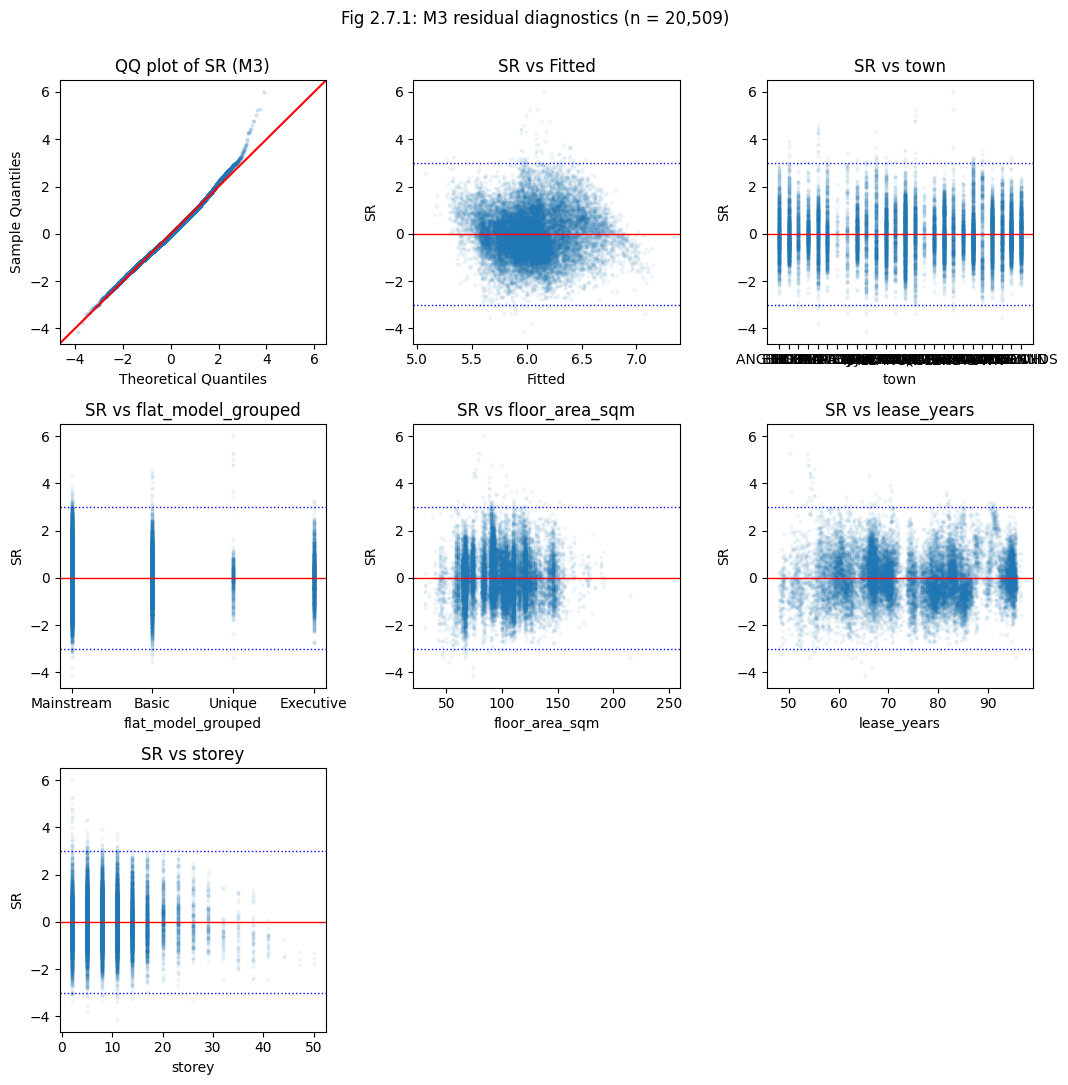

no. |SR|>3: 87
cooks > 1 number : 0
max cooks : 0.00736994062023188
1     0.91
2     0.88
3     0.89
4     0.98
5     1.04
6     0.95
7     1.00
8     1.16
9     1.12
10    0.95
dtype: float64
VIF test of M3


,variable,VIF
20,C(town)[T.SENGKANG],2.97
17,C(town)[T.PUNGGOL],2.87
13,C(town)[T.JURONG WEST],2.79
24,C(town)[T.WOODLANDS],2.71
22,C(town)[T.TAMPINES],2.43
30,lease_years,2.31
25,C(town)[T.YISHUN],2.27
1,C(town)[T.BEDOK],2.13
27,C(flat_model_grouped)[T.Mainstream],2.10
26,C(flat_model_grouped)[T.Executive],2.08


In [24]:
M3 = smf.ols('np.log(price_k) ~ C(town) + C(flat_model_grouped) + np.sqrt(floor_area_sqm) + lease_years + storey', data = df_train).fit()
print(M3.summary())
print(sm.stats.anova_lm(M3, typ = 2))
sr_M3 = SR(M3)

resid_plots(M3, df_train, ['town', 'flat_model_grouped', 'floor_area_sqm', 'lease_years', 'storey'],
            title="M3", fig_label="Fig 2.7.1")

##Check number of outliers 
print("no. |SR|>3:", np.sum(np.abs(sr_M3) > 3))

cooks = M3.get_influence().cooks_distance[0]
print(f'cooks > 1 number : {(cooks > 1).sum()}')  
print(f'max cooks : {max(cooks)}')


sr3 = pd.Series(SR(M3), index=M3.fittedvalues.index)
q = pd.qcut(M3.fittedvalues, 10, labels=False) + 1
print(sr3.groupby(q).std().round(2))

print('VIF test of M3')
vif_table(M3)

                            OLS Regression Results                            
Dep. Variable:        np.log(price_k)   R-squared:                       0.879
Model:                            OLS   Adj. R-squared:                  0.879
Method:                 Least Squares   F-statistic:                     4808.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:35:51   Log-Likelihood:                 16480.
No. Observations:               20509   AIC:                        -3.290e+04
Df Residuals:                   20477   BIC:                        -3.264e+04
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

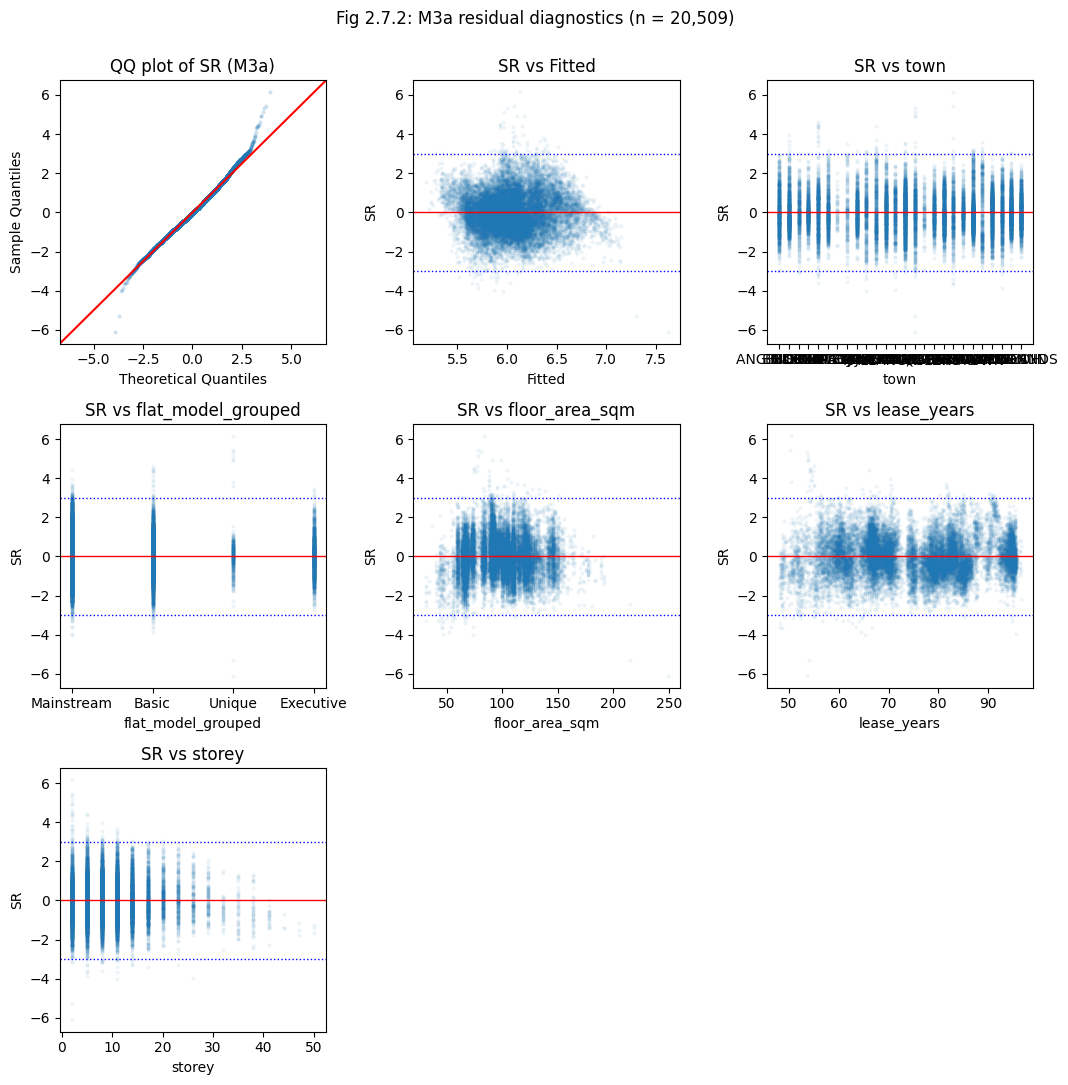

In [25]:
M3a = smf.ols('np.log(price_k) ~ C(town) + C(flat_model_grouped) + floor_area_sqm + lease_years + storey', data = df_train).fit()
print(M3a.summary())
print(sm.stats.anova_lm(M3a, typ = 2))
sr_M3a = resid_plots(M3a, df_train, ['town', 'flat_model_grouped', 'floor_area_sqm', 'lease_years', 'storey'],
                     title="M3a", fig_label="Fig 2.7.2")

## Part 3: Evaluate Model using Test Data


The final model M3, fitted on the 2017 training data, is used to predict the resale prices of the test data (Jan–Mar 2018, n = 4,136). 

On the log scale (the response of the model), RMSE = 0.1118 and $R^2_{test}$ = 0.8872; 

For comparison, the training RMSE is 0.1062 and the training $R^2$ is 0.8839. 

The test error is only slightly higher than the training error (about 5%), and $R^2_{test}$ is as high as the training $R^2$, so the model does not overfit and predicts unseen data well. 


In [26]:
df_test = pd.read_csv(TEST_PATH)

df_test['price_k'] = df_test['resale_price'] / 1000

def lease_years(s):
    p=s.split(); y=int(p[0]); mth=int(p[2]) if len(p)>2 else 0
    return y+mth/12

def midpoint_storey(s):
    p=s.split(); a=int(p[0]); b=int(p[2])
    return (a + b) / 2


def month_from_date(s):
    p=s.split('-'); return int(p[1])

df_test['lease_years'] = df_test['remaining_lease'].apply(lease_years)
df_test['storey'] = df_test['storey_range'].apply(midpoint_storey)
df_test['month'] = df_test['month'].apply(month_from_date)
df_test.head()
df_test['flat_model_grouped'] = df_test['flat_model'].map(flat_model_mapping)

pred_log = M3.predict(df_test)    # M3 fitted on df_train, 2018 only used as input

y_log = np.log(df_test["price_k"])      # response of the model


def test_metrics(y, yhat):
    sse = ((y - yhat) ** 2).sum()
    sst = ((y - y.mean()) ** 2).sum()
    rmse = np.sqrt(sse / len(y))
    r2 = 1 - sse / sst
    return rmse, r2

# (a) log scale (the model's response)
rmse_log, r2_log = test_metrics(y_log, pred_log)


print(f"n_test = {len(df_test)}")
print(f"log scale   : RMSE = {rmse_log:.4f} | R2_test = {r2_log:.4f}")


# ---------- 3. for comparison: the same metrics on the training data ----------
rmse_tr_log, r2_tr_log = test_metrics(np.log(df_train["price_k"]), M3.fittedvalues)
print(f"train (log) : RMSE = {rmse_tr_log:.4f} | R2 = {r2_tr_log:.4f}")

n_test = 4136
log scale   : RMSE = 0.1118 | R2_test = 0.8872
train (log) : RMSE = 0.1062 | R2 = 0.8839
